
# Klasifikasi Land Use/Land Cover (LULC) Jawa Timur

## 1. Business Understanding

### 1.1 Latar Belakang
Pemanfaatan citra satelit Sentinel-2 dan Machine Learning digunakan untuk mengidentifikasi serta memetakan tutupan lahan di wilayah Jawa Timur.

### 1.2 Tujuan
Mengembangkan model klasifikasi tutupan lahan menjadi lima kelas, yaitu bangunan, lahan pertanian, badan air, hutan, dan hutan mangrove.

### 1.3 Fokus Penelitian
Mengevaluasi penggunaan band Sentinel-2 B4, B8A, dan B11 untuk membedakan hutan mangrove dengan hutan biasa.

### 1.4 Hasil yang Diharapkan
- Model klasifikasi tutupan lahan.
- Peta satelit dengan layer hasil klasifikasi.
- Layer GeoJSON yang dapat difilter berdasarkan kelas.
- Aplikasi interaktif menggunakan Leaflet dan Streamlit.
- Evaluasi performa model klasifikasi.


In [37]:
import pandas as pd
from pathlib import Path

# Lokasi dataset
CSV_PATH = Path("../data/sentinel_bands/fitur_lulc_jatim.csv")

# Membaca dataset
df = pd.read_csv(CSV_PATH)

# Menampilkan ukuran dataset
print("Jumlah baris dan kolom:", df.shape)

# Menampilkan nama kolom
print("\nNama kolom:")
print(df.columns.tolist())

# Menampilkan lima baris pertama
display(df.head())


Jumlah baris dan kolom: (234, 16)

Nama kolom:
['class', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI', 'NDMI']


,class,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDMI
0,build up,0.088406,0.113573,0.120504,0.163613,0.245380,0.273172,0.274390,0.295580,0.305551,0.236997,0.384372,-0.407889,-0.458009,0.056042,-0.056042
1,build up,0.120352,0.140737,0.141277,0.176431,0.249221,0.270677,0.263768,0.284525,0.289914,0.231528,0.312946,-0.313368,-0.357631,0.046475,-0.046475
2,build up,0.068997,0.095945,0.118226,0.162432,0.245970,0.281186,0.274400,0.300232,0.293182,0.225205,0.397961,-0.478168,-0.507433,0.034234,-0.034234
3,build up,0.097159,0.123640,0.144491,0.187808,0.258830,0.289684,0.280869,0.308453,0.335466,0.279793,0.331948,-0.398112,-0.471630,0.086799,-0.086799
4,build up,0.141139,0.172682,0.187683,0.214553,0.283210,0.313567,0.311547,0.327936,0.306013,0.237056,0.249632,-0.289601,-0.281574,-0.008987,0.008987


In [38]:
# 1. Memeriksa nilai kosong
print("=== NILAI KOSONG ===")
print(df.isnull().sum())

# 2. Memeriksa data duplikat
print("\n=== DATA DUPLIKAT ===")
print("Jumlah baris duplikat:", df.duplicated().sum())

# 3. Memeriksa distribusi kelas
print("\n=== DISTRIBUSI KELAS ===")
print(df["class"].value_counts())

# 4. Memeriksa statistik fitur numerik
print("\n=== STATISTIK FITUR ===")
display(df.describe().round(4))


=== NILAI KOSONG ===
class    0
B2       0
B3       0
B4       0
B5       0
B6       0
B7       0
B8       0
B8A      0
B11      0
B12      0
NDVI     0
NDWI     0
MNDWI    0
NDBI     0
NDMI     0
dtype: int64

=== DATA DUPLIKAT ===
Jumlah baris duplikat: 0

=== DISTRIBUSI KELAS ===
class
fram land         61
build up          50
forest            50
water body        50
hutan mangrove    23
Name: count, dtype: int64

=== STATISTIK FITUR ===


,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDMI
count,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000,234.0000
mean,0.0571,0.0821,0.0760,0.1221,0.2156,0.2477,0.2440,0.2654,0.1997,0.1325,0.4609,-0.4149,-0.3367,-0.1055,0.1055
std,0.0245,0.0268,0.0379,0.0382,0.0653,0.0773,0.0789,0.0868,0.0891,0.0757,0.2771,0.2993,0.2777,0.1879,0.1879
min,0.0232,0.0273,0.0135,0.0152,0.0124,0.0143,0.0131,0.0118,0.0155,0.0119,-0.5497,-0.7620,-0.5837,-0.5369,-0.6069
25%,0.0405,0.0625,0.0452,0.0949,0.2103,0.2415,0.2373,0.2585,0.1300,0.0640,0.3387,-0.5996,-0.5240,-0.2200,-0.0086
50%,0.0533,0.0811,0.0712,0.1225,0.2382,0.2701,0.2658,0.2893,0.2255,0.1353,0.4933,-0.4971,-0.4538,-0.0782,0.0782
75%,0.0658,0.0940,0.1011,0.1470,0.2542,0.2962,0.2912,0.3177,0.2722,0.1870,0.6447,-0.3727,-0.2960,0.0086,0.2200
max,0.1739,0.1895,0.1900,0.2253,0.2888,0.3472,0.3513,0.3806,0.3360,0.2798,0.8738,0.6988,0.5604,0.6069,0.5369


In [39]:

# Memeriksa hubungan NDBI dan NDMI
print("Korelasi NDBI dengan NDMI:")
print(df[["NDBI", "NDMI"]].corr().round(4))

# Memeriksa apakah keduanya saling berlawanan
selisih = (df["NDBI"] + df["NDMI"]).abs()

print("\nNilai maksimum |NDBI + NDMI|:")
print(selisih.max())

# Memeriksa nama label kelas
print("\nLabel kelas:")
print(sorted(df["class"].unique()))


Korelasi NDBI dengan NDMI:
      NDBI  NDMI
NDBI   1.0  -1.0
NDMI  -1.0   1.0

Nilai maksimum |NDBI + NDMI|:
0.0

Label kelas:
['build up', 'forest', 'fram land', 'hutan mangrove', 'water body']


In [40]:

# Membuat salinan data agar data asli tetap aman
data = df.copy()

# Menyeragamkan nama kelas lahan pertanian
data["class"] = data["class"].replace({
    "fram land": "farm land"
})

# Memeriksa label kelas setelah perbaikan
print("Label kelas setelah standardisasi:")
print(sorted(data["class"].unique()))

print("\nDistribusi kelas:")
print(data["class"].value_counts())


Label kelas setelah standardisasi:
['build up', 'farm land', 'forest', 'hutan mangrove', 'water body']

Distribusi kelas:
class
farm land         61
build up          50
forest            50
water body        50
hutan mangrove    23
Name: count, dtype: int64


In [41]:

# Menentukan kolom target
target = "class"

# Menentukan fitur spektral dan indeks
fitur_lengkap = [
    "B2", "B3", "B4", "B5", "B6",
    "B7", "B8", "B8A", "B11", "B12",
    "NDVI", "NDWI", "MNDWI", "NDBI", "NDMI"
]

# Memisahkan fitur dan target
X = data[fitur_lengkap].copy()
y = data[target].copy()

# Memeriksa hasil pemisahan
print("Ukuran fitur (X):", X.shape)
print("Ukuran target (y):", y.shape)

print("\nContoh fitur:")
display(X.head())

print("\nContoh target:")
display(y.head())


Ukuran fitur (X): (234, 15)
Ukuran target (y): (234,)

Contoh fitur:


,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,NDVI,NDWI,MNDWI,NDBI,NDMI
0,0.088406,0.113573,0.120504,0.163613,0.245380,0.273172,0.274390,0.295580,0.305551,0.236997,0.384372,-0.407889,-0.458009,0.056042,-0.056042
1,0.120352,0.140737,0.141277,0.176431,0.249221,0.270677,0.263768,0.284525,0.289914,0.231528,0.312946,-0.313368,-0.357631,0.046475,-0.046475
2,0.068997,0.095945,0.118226,0.162432,0.245970,0.281186,0.274400,0.300232,0.293182,0.225205,0.397961,-0.478168,-0.507433,0.034234,-0.034234
3,0.097159,0.123640,0.144491,0.187808,0.258830,0.289684,0.280869,0.308453,0.335466,0.279793,0.331948,-0.398112,-0.471630,0.086799,-0.086799
4,0.141139,0.172682,0.187683,0.214553,0.283210,0.313567,0.311547,0.327936,0.306013,0.237056,0.249632,-0.289601,-0.281574,-0.008987,0.008987



Contoh target:


0    build up
1    build up
2    build up
3    build up
4    build up
Name: class, dtype: object

In [42]:

# Fitur lengkap tanpa NDMI yang redundan
fitur_model = [
    "B2", "B3", "B4", "B5", "B6",
    "B7", "B8", "B8A", "B11", "B12",
    "NDVI", "NDWI", "MNDWI", "NDBI"
]

X_lengkap = data[fitur_model].copy()

# Fitur khusus sesuai arahan dosen
fitur_mangrove = ["B4", "B8A", "B11"]
X_mangrove = data[fitur_mangrove].copy()

print("Jumlah fitur model lengkap:", len(fitur_model))
print("Kolom model lengkap:", fitur_model)

print("\nJumlah fitur model mangrove:", len(fitur_mangrove))
print("Kolom model mangrove:", fitur_mangrove)

print("\nPemeriksaan nilai tak hingga:")
print("Model lengkap:", np.isinf(X_lengkap.to_numpy()).sum())
print("Model mangrove:", np.isinf(X_mangrove.to_numpy()).sum())


Jumlah fitur model lengkap: 14
Kolom model lengkap: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'MNDWI', 'NDBI']

Jumlah fitur model mangrove: 3
Kolom model mangrove: ['B4', 'B8A', 'B11']

Pemeriksaan nilai tak hingga:
Model lengkap: 0
Model mangrove: 0


In [43]:

from sklearn.model_selection import train_test_split

# Membagi data: 75% latih dan 25% uji
X_train, X_test, y_train, y_test = train_test_split(
    X_lengkap,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Memeriksa ukuran hasil pembagian
print("Jumlah data awal :", len(data))
print("Data latih       :", len(X_train))
print("Data uji         :", len(X_test))

print("\nDistribusi kelas data latih:")
print(y_train.value_counts())

print("\nDistribusi kelas data uji:")
print(y_test.value_counts())



Jumlah data awal : 234
Data latih       : 175
Data uji         : 59

Distribusi kelas data latih:
class
farm land         46
build up          38
water body        37
forest            37
hutan mangrove    17
Name: count, dtype: int64

Distribusi kelas data uji:
class
farm land         15
water body        13
forest            13
build up          12
hutan mangrove     6
Name: count, dtype: int64


In [44]:

from sklearn.ensemble import RandomForestClassifier

# Membuat model Random Forest
rf_lengkap = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Melatih model menggunakan data latih
rf_lengkap.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih.")
print("Jumlah pohon:", rf_lengkap.n_estimators)
print("Jumlah fitur:", rf_lengkap.n_features_in_)
print("Jumlah kelas:", len(rf_lengkap.classes_))
print("Kelas model:", rf_lengkap.classes_)


Model Random Forest berhasil dilatih.
Jumlah pohon: 300
Jumlah fitur: 14
Jumlah kelas: 5
Kelas model: ['build up' 'farm land' 'forest' 'hutan mangrove' 'water body']


Akurasi model: 0.8983 (89.83%)

Laporan klasifikasi:
                precision    recall  f1-score   support

      build up       0.80      1.00      0.89        12
     farm land       0.92      0.80      0.86        15
        forest       1.00      0.92      0.96        13
hutan mangrove       0.83      0.83      0.83         6
    water body       0.92      0.92      0.92        13

      accuracy                           0.90        59
     macro avg       0.90      0.90      0.89        59
  weighted avg       0.91      0.90      0.90        59



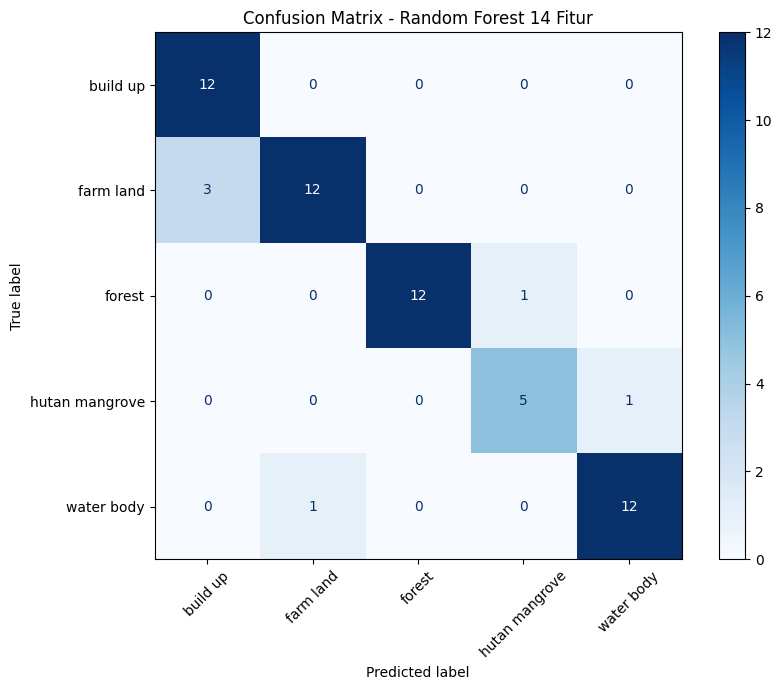

In [45]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Prediksi data uji
y_pred = rf_lengkap.predict(X_test)

# Menghitung akurasi
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi model: {akurasi:.4f} ({akurasi * 100:.2f}%)")

# Laporan evaluasi setiap kelas
print("\nLaporan klasifikasi:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=rf_lengkap.classes_)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=rf_lengkap.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Confusion Matrix - Random Forest 14 Fitur")
plt.tight_layout()
plt.show()


In [46]:

# Membagi data dengan fitur khusus mangrove
X_train_mangrove, X_test_mangrove, y_train_mangrove, y_test_mangrove = train_test_split(
    X_mangrove,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# Membuat model Random Forest khusus B4, B8A, B11
rf_mangrove = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Melatih model
rf_mangrove.fit(X_train_mangrove, y_train_mangrove)

# Prediksi data uji
y_pred_mangrove = rf_mangrove.predict(X_test_mangrove)

# Evaluasi
akurasi_mangrove = accuracy_score(y_test_mangrove, y_pred_mangrove)

print(f"Akurasi model B4-B8A-B11: {akurasi_mangrove:.4f} ({akurasi_mangrove * 100:.2f}%)")

print("\nLaporan klasifikasi:")
print(classification_report(
    y_test_mangrove,
    y_pred_mangrove,
    zero_division=0
))


Akurasi model B4-B8A-B11: 0.8644 (86.44%)

Laporan klasifikasi:
                precision    recall  f1-score   support

      build up       0.80      1.00      0.89        12
     farm land       0.92      0.80      0.86        15
        forest       0.93      1.00      0.96        13
hutan mangrove       1.00      0.50      0.67         6
    water body       0.79      0.85      0.81        13

      accuracy                           0.86        59
     macro avg       0.89      0.83      0.84        59
  weighted avg       0.88      0.86      0.86        59



In [47]:

from sklearn.metrics import f1_score

# Membuat ringkasan perbandingan model
hasil_perbandingan = pd.DataFrame([
    {
        "Model": "Random Forest - 14 fitur",
        "Jumlah Fitur": 14,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1 Mangrove": f1_score(
            y_test, y_pred,
            labels=["hutan mangrove"],
            average="macro",
            zero_division=0
        )
    },
    {
        "Model": "Random Forest - B4, B8A, B11",
        "Jumlah Fitur": 3,
        "Accuracy": accuracy_score(y_test_mangrove, y_pred_mangrove),
        "Macro F1": f1_score(
            y_test_mangrove, y_pred_mangrove,
            average="macro", zero_division=0
        ),
        "F1 Mangrove": f1_score(
            y_test_mangrove, y_pred_mangrove,
            labels=["hutan mangrove"],
            average="macro",
            zero_division=0
        )
    }
])

display(hasil_perbandingan.round(4))


,Model,Jumlah Fitur,Accuracy,Macro F1,F1 Mangrove
0,Random Forest - 14 fitur,14,0.8983,0.8925,0.8333
1,"Random Forest - B4, B8A, B11",3,0.8644,0.8381,0.6667


In [48]:

# Mengambil feature importance dari model Random Forest lengkap
importance = pd.DataFrame({
    "Fitur": X_train.columns,
    "Importance": rf_lengkap.feature_importances_
})

# Mengurutkan fitur dari yang paling berpengaruh
importance = importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

display(importance.round(4))


,Fitur,Importance
0,B12,0.1360
1,B11,0.1239
2,MNDWI,0.1193
3,NDBI,0.1192
4,B4,0.0634
5,NDWI,0.0631
6,B5,0.0597
7,B3,0.0541
8,B8A,0.0517
9,B6,0.0493


In [49]:

from pathlib import Path

# Membuat folder output jika belum tersedia
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Menyimpan tabel perbandingan model
hasil_perbandingan.to_csv(
    output_dir / "perbandingan_model.csv",
    index=False
)

# Menyimpan feature importance
importance.to_csv(
    output_dir / "feature_importance.csv",
    index=False
)

print("File evaluasi berhasil disimpan:")
print(output_dir / "perbandingan_model.csv")
print(output_dir / "feature_importance.csv")


File evaluasi berhasil disimpan:
..\data\processed\perbandingan_model.csv
..\data\processed\feature_importance.csv


In [50]:

import joblib
from pathlib import Path

# Membuat folder penyimpanan model
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Menyimpan model Random Forest lengkap
joblib.dump(
    {
        "model": rf_lengkap,
        "features": fitur_model,
        "classes": list(rf_lengkap.classes_),
        "accuracy": accuracy_score(y_test, y_pred)
    },
    model_dir / "random_forest_lulc.joblib"
)

print("Model berhasil disimpan.")
print("Lokasi:", model_dir / "random_forest_lulc.joblib")


Model berhasil disimpan.
Lokasi: ..\models\random_forest_lulc.joblib


In [51]:

from pathlib import Path

# Memeriksa file citra Sentinel-2
band_dir = Path("../data/sentinel_bands")

print("Folder citra:", band_dir.resolve())
print("\nDaftar file:")

for file in sorted(band_dir.iterdir()):
    if file.is_file():
        print(file.name)


Folder citra: D:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR revisi\data\sentinel_bands

Daftar file:
fitur_lulc_jatim.csv


In [52]:

import rasterio
from pathlib import Path

# Lokasi raster yang sudah tersedia
raster_path = Path("../data/lulc_jawa_timur_rf_revisi.tif")

# Memeriksa metadata raster
with rasterio.open(raster_path) as src:
    print("Nama file:", raster_path.name)
    print("CRS:", src.crs)
    print("Jumlah band:", src.count)
    print("Ukuran raster (lebar, tinggi):", src.width, src.height)
    print("Tipe data:", src.dtypes)
    print("NoData:", src.nodata)
    print("Batas koordinat:", src.bounds)
    print("Resolusi:", src.res)


Nama file: lulc_jawa_timur_rf_revisi.tif
CRS: EPSG:4326
Jumlah band: 1
Ukuran raster (lebar, tinggi): 29852 20725
Tipe data: ('uint8',)
NoData: 255.0
Batas koordinat: BoundingBox(left=110.89863879206634, bottom=-8.780852239211498, right=116.26194036437353, top=-5.057335386536082)
Resolusi: (0.0001796630568239043, 0.0001796630568239043)


In [53]:

import numpy as np
import rasterio

with rasterio.open(raster_path) as src:
    raster = src.read(1)

# Menghitung nilai unik dan jumlah piksel setiap nilai
nilai, jumlah = np.unique(raster, return_counts=True)

print("Nilai unik raster dan jumlah piksel:")
for v, n in zip(nilai, jumlah):
    print(f"Nilai {v}: {n:,} piksel")

print("\nJumlah piksel total:", raster.size)
print("Jumlah piksel NoData:", np.sum(raster == 255))


Nilai unik raster dan jumlah piksel:
Nilai 0: 20,092,679 piksel
Nilai 1: 9,054,805 piksel
Nilai 2: 22,749,549 piksel
Nilai 3: 67,543,838 piksel
Nilai 4: 1,939,089 piksel
Nilai 255: 497,302,740 piksel

Jumlah piksel total: 618682700
Jumlah piksel NoData: 497302740


In [54]:

# Membuat ringkasan distribusi nilai raster
ringkasan_raster = pd.DataFrame({
    "Nilai Raster": nilai,
    "Jumlah Piksel": jumlah
})

ringkasan_raster["Persentase (%)"] = (
    ringkasan_raster["Jumlah Piksel"] / raster.size * 100
)

display(ringkasan_raster.round(2))


,Nilai Raster,Jumlah Piksel,Persentase (%)
0,0,20092679,3.25
1,1,9054805,1.46
2,2,22749549,3.68
3,3,67543838,10.92
4,4,1939089,0.31
5,255,497302740,80.38


In [55]:

from pathlib import Path

# Mencari semua file raster dalam folder data
data_dir = Path("../data")

raster_files = [
    p for p in data_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in [".tif", ".tiff", ".jp2"]
]

print("Daftar file raster yang tersedia:\n")

for file in raster_files:
    print(file.relative_to(data_dir))



Daftar file raster yang tersedia:

lulc_jawa_timur_rf_revisi.tif


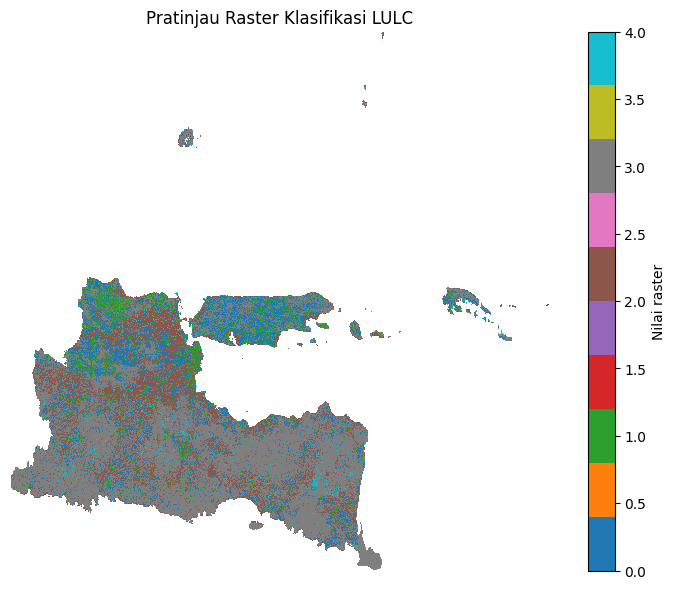

In [56]:

import matplotlib.pyplot as plt
import rasterio
import numpy as np

raster_path = "../data/lulc_jawa_timur_rf_revisi.tif"

with rasterio.open(raster_path) as src:
    # Baca sebagian raster agar visualisasi lebih ringan
    raster_preview = src.read(
        1,
        out_shape=(1, 1000, 1000),
        resampling=rasterio.enums.Resampling.nearest
    )

# Tampilkan nilai kelas; 255 adalah NoData
plt.figure(figsize=(10, 7))
plt.imshow(
    np.ma.masked_equal(raster_preview, 255),
    cmap="tab10",
    interpolation="nearest"
)
plt.title("Pratinjau Raster Klasifikasi LULC")
plt.axis("off")
plt.colorbar(label="Nilai raster")
plt.show()


In [57]:

# Memeriksa nilai kelas selain NoData
with rasterio.open(raster_path) as src:
    raster = src.read(1)

nilai_kelas = np.unique(raster[raster != 255])

print("Nilai kelas yang tersedia:", nilai_kelas)
print("Jumlah kelas yang tersedia:", len(nilai_kelas))


Nilai kelas yang tersedia: [0 1 2 3 4]
Jumlah kelas yang tersedia: 5


In [58]:

import geopandas as gpd
from pathlib import Path

geojson_path = Path("../data/geojson/jawatimur.geojson")
gdf = gpd.read_file(geojson_path)

print("Jumlah fitur GeoJSON:", len(gdf))
print("\nNama kolom:")
print(gdf.columns.tolist())

print("\nDistribusi kelas pada GeoJSON:")
print(gdf["class"].value_counts())


Jumlah fitur GeoJSON: 261

Nama kolom:
['class', 'geometry']

Distribusi kelas pada GeoJSON:
class
fram land         61
build up          50
hutan mangrove    50
water body        50
forest            50
Name: count, dtype: int64


In [59]:

from rasterio.mask import mask
from collections import Counter

# Memastikan CRS GeoJSON sama dengan raster
with rasterio.open(raster_path) as src:
    if gdf.crs != src.crs:
        gdf_raster = gdf.to_crs(src.crs)
    else:
        gdf_raster = gdf.copy()

    hasil_cocok = []

    for _, row in gdf_raster.iterrows():
        try:
            out_image, _ = mask(
                src,
                [row.geometry],
                crop=True,
                filled=False
            )

            values = out_image[0].compressed()
            values = values[(values != 255)]

            if len(values) > 0:
                counts = Counter(values.tolist())
                kelas_dominan = counts.most_common(1)[0][0]
                hasil_cocok.append({
                    "class_geojson": row["class"],
                    "nilai_raster_dominan": kelas_dominan
                })

        except Exception:
            continue

hasil_cocok_df = pd.DataFrame(hasil_cocok)

print("Jumlah poligon yang berhasil dicocokkan:", len(hasil_cocok_df))
display(
    pd.crosstab(
        hasil_cocok_df["class_geojson"],
        hasil_cocok_df["nilai_raster_dominan"]
    )
)


Jumlah poligon yang berhasil dicocokkan: 229


nilai_raster_dominan,0,1,2,3,4
class_geojson,,,,,
build up,3,43,0,2,0
forest,0,1,0,49,0
fram land,52,3,0,3,0
hutan mangrove,0,0,1,0,22
water body,0,1,48,1,0


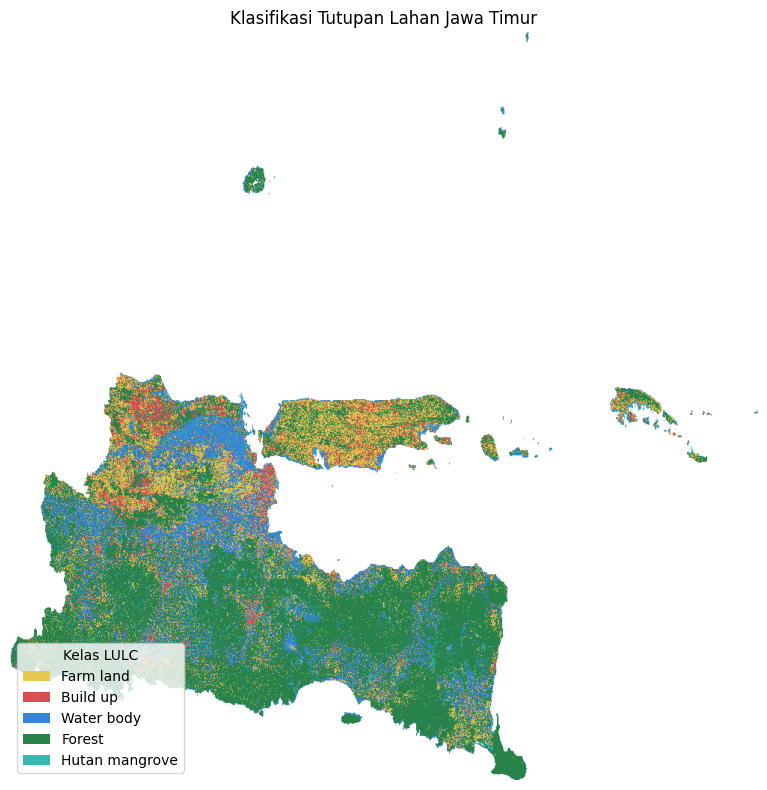

In [60]:

from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import rasterio

# Membaca sebagian raster untuk visualisasi
with rasterio.open(raster_path) as src:
    raster_preview = src.read(
        1,
        out_shape=(1, 1000, 1000),
        resampling=rasterio.enums.Resampling.nearest
    )

# Pemetaan sementara berdasarkan hasil pencocokan GeoJSON
nama_kelas = {
    0: "Farm land",
    1: "Build up",
    2: "Water body",
    3: "Forest",
    4: "Hutan mangrove"
}

warna_kelas = {
    0: "#E6C84F",
    1: "#D94F4F",
    2: "#3685D6",
    3: "#27834A",
    4: "#35B8B0"
}

# Mengubah NoData menjadi transparan
raster_tampil = np.ma.masked_equal(raster_preview, 255)

cmap = ListedColormap([warna_kelas[i] for i in range(5)])
cmap.set_bad("white")

plt.figure(figsize=(12, 8))
plt.imshow(raster_tampil, cmap=cmap, vmin=-0.5, vmax=4.5)
plt.title("Klasifikasi Tutupan Lahan Jawa Timur")
plt.axis("off")

legenda = [
    Patch(facecolor=warna_kelas[i], label=nama_kelas[i])
    for i in range(5)
]

plt.legend(handles=legenda, loc="lower left", title="Kelas LULC")
plt.tight_layout()
plt.show()


In [61]:

# Menghitung jumlah piksel untuk setiap kelas
with rasterio.open(raster_path) as src:
    raster = src.read(1)

total_valid = np.sum(raster != 255)

print("Total piksel valid:", f"{total_valid:,}")
print("\nDistribusi kelas hasil klasifikasi:")

for kelas_id, nama in nama_kelas.items():
    jumlah_piksel = np.sum(raster == kelas_id)
    persentase = jumlah_piksel / total_valid * 100

    print(
        f"{nama:18s}: "
        f"{jumlah_piksel:>12,} piksel "
        f"({persentase:.2f}%)"
    )


Total piksel valid: 121,379,960

Distribusi kelas hasil klasifikasi:
Farm land         :   20,092,679 piksel (16.55%)
Build up          :    9,054,805 piksel (7.46%)
Water body        :   22,749,549 piksel (18.74%)
Forest            :   67,543,838 piksel (55.65%)
Hutan mangrove    :    1,939,089 piksel (1.60%)


In [62]:

print("CRS GeoJSON:", gdf.crs)
print("CRS raster:", rasterio.open(raster_path).crs)

print("\nBatas GeoJSON:")
print(gdf.total_bounds)

with rasterio.open(raster_path) as src:
    print("\nBatas raster:")
    print(src.bounds)


CRS GeoJSON: EPSG:4326
CRS raster: EPSG:4326

Batas GeoJSON:
[111.214371  -8.291241 114.358055  -6.847228]

Batas raster:
BoundingBox(left=110.89863879206634, bottom=-8.780852239211498, right=116.26194036437353, top=-5.057335386536082)


In [65]:

import folium
from IPython.display import display

# Titik tengah wilayah digitasi
minx, miny, maxx, maxy = gdf.total_bounds
titik_tengah = [(miny + maxy) / 2, (minx + maxx) / 2]

# Membuat peta dengan basemap satelit
peta = folium.Map(
    location=titik_tengah,
    zoom_start=8,
    tiles=None
)

# Menambahkan basemap satelit Esri
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics",
    name="Citra Satelit",
    overlay=False,
    control=True
).add_to(peta)

# Warna setiap kelas GeoJSON
warna_geojson = {
    "build up": "#D94F4F",
    "fram land": "#E6C84F",
    "water body": "#3685D6",
    "forest": "#27834A",
    "hutan mangrove": "#35B8B0"
}

# Membuat satu layer terpisah untuk setiap kelas
for kelas, warna in warna_geojson.items():
    data_kelas = gdf[gdf["class"] == kelas]

    if not data_kelas.empty:
        layer = folium.FeatureGroup(
            name=kelas.title(),
            show=True
        )

        folium.GeoJson(
            data_kelas.to_json(),
            style_function=lambda feature, warna=warna: {
                "fillColor": warna,
                "color": warna,
                "weight": 1,
                "fillOpacity": 0.55
            },
            tooltip=folium.GeoJsonTooltip(
                fields=["class"],
                aliases=["Kelas:"]
            )
        ).add_to(layer)

        layer.add_to(peta)

# Menambahkan kontrol layer
folium.LayerControl(collapsed=False).add_to(peta)

# Menyesuaikan tampilan dengan batas GeoJSON
peta.fit_bounds([[miny, minx], [maxy, maxx]])

display(peta)


In [66]:

from pathlib import Path

# Simpan peta Folium ke file HTML
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

peta_path = output_dir / "peta_geojson_lulc.html"
peta.save(str(peta_path))

print("Peta disimpan di:")
print(peta_path.resolve())
print("File tersedia:", peta_path.exists())


Peta disimpan di:
D:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR revisi\data\processed\peta_geojson_lulc.html
File tersedia: True


In [69]:

import webbrowser

webbrowser.open(peta_path.resolve().as_uri())


True

In [73]:

import numpy as np
import rasterio
import folium
import io
import base64

from pathlib import Path
from PIL import Image
from folium.raster_layers import ImageOverlay

# Lokasi raster klasifikasi
raster_path = Path("../data/lulc_jawa_timur_rf_revisi.tif")

# Ukuran maksimum untuk pratinjau peta web
MAX_SIZE = 1800

with rasterio.open(raster_path) as src:
    scale = min(1, MAX_SIZE / max(src.width, src.height))

    preview_width = max(1, int(src.width * scale))
    preview_height = max(1, int(src.height * scale))

    raster_preview = src.read(
        1,
        out_shape=(preview_height, preview_width),
        resampling=rasterio.enums.Resampling.nearest
    )

    bounds = src.bounds

# Pemetaan kelas sementara berdasarkan hasil pencocokan GeoJSON
nama_kelas = {
    0: "Farm land",
    1: "Build up",
    2: "Water body",
    3: "Forest",
    4: "Hutan mangrove"
}

warna_kelas = {
    0: (230, 200, 79),
    1: (217, 79, 79),
    2: (54, 133, 214),
    3: (39, 131, 74),
    4: (53, 184, 176)
}

# Membuat peta dasar
tengah = [
    (bounds.bottom + bounds.top) / 2,
    (bounds.left + bounds.right) / 2
]

peta_lulc = folium.Map(
    location=tengah,
    zoom_start=8,
    tiles=None
)

# Basemap citra satelit
folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "World_Imagery/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri, Maxar, Earthstar Geographics",
    name="Citra Satelit",
    overlay=False
).add_to(peta_lulc)

# Membuat layer ON/OFF untuk setiap kelas
for kelas_id, nama in nama_kelas.items():

    # Gambar transparan untuk satu kelas saja
    rgba = np.zeros(
        (preview_height, preview_width, 4),
        dtype=np.uint8
    )

    mask_kelas = raster_preview == kelas_id

    rgba[mask_kelas, :3] = warna_kelas[kelas_id]
    rgba[mask_kelas, 3] = 150

    # Konversi gambar RGBA menjadi PNG Base64
    buffer = io.BytesIO()
    Image.fromarray(rgba).save(buffer, format="PNG")

    gambar_base64 = base64.b64encode(
        buffer.getvalue()
    ).decode("utf-8")

    # Layer terpisah untuk setiap kelas
    layer = folium.FeatureGroup(
        name=f"Klasifikasi: {nama}",
        show=True
    )

    ImageOverlay(
        image=f"data:image/png;base64,{gambar_base64}",
        bounds=[
            [bounds.bottom, bounds.left],
            [bounds.top, bounds.right]
        ],
        name=nama,
        opacity=1.0,
        interactive=False,
        cross_origin=False
    ).add_to(layer)

    # Tambahkan layer ke peta
    layer.add_to(peta_lulc)

# Kontrol checkbox
folium.LayerControl(collapsed=False).add_to(peta_lulc)

# Fokus pada cakupan raster
peta_lulc.fit_bounds([
    [bounds.bottom, bounds.left],
    [bounds.top, bounds.right]
])

# Simpan peta sebagai HTML
output_path = Path("../data/processed/peta_lulc_interaktif.html")
output_path.parent.mkdir(parents=True, exist_ok=True)
peta_lulc.save(str(output_path))

print("Peta berhasil dibuat:", output_path.resolve())
print("Ukuran pratinjau:", preview_width, "x", preview_height)
print("Jumlah layer klasifikasi:", len(nama_kelas))


Peta berhasil dibuat: D:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR revisi\data\processed\peta_lulc_interaktif.html
Ukuran pratinjau: 1800 x 1249
Jumlah layer klasifikasi: 5


In [4]:
from pathlib import Path
import rasterio

RASTER_PATH = Path(
    r"D:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR revisi\data\lulc_jawa_timur_rf_revisi.tif"
)

print("File ditemukan:", RASTER_PATH.exists())

if RASTER_PATH.exists():
    with rasterio.open(RASTER_PATH) as src:
        print("CRS:", src.crs)
        print("Ukuran raster:", src.width, "x", src.height)
        print("Jumlah band:", src.count)
        print("Resolusi:", src.res)
        print("NoData:", src.nodata)

File ditemukan: True
CRS: EPSG:4326
Ukuran raster: 29852 x 20725
Jumlah band: 1
Resolusi: (0.0001796630568239043, 0.0001796630568239043)
NoData: 255.0


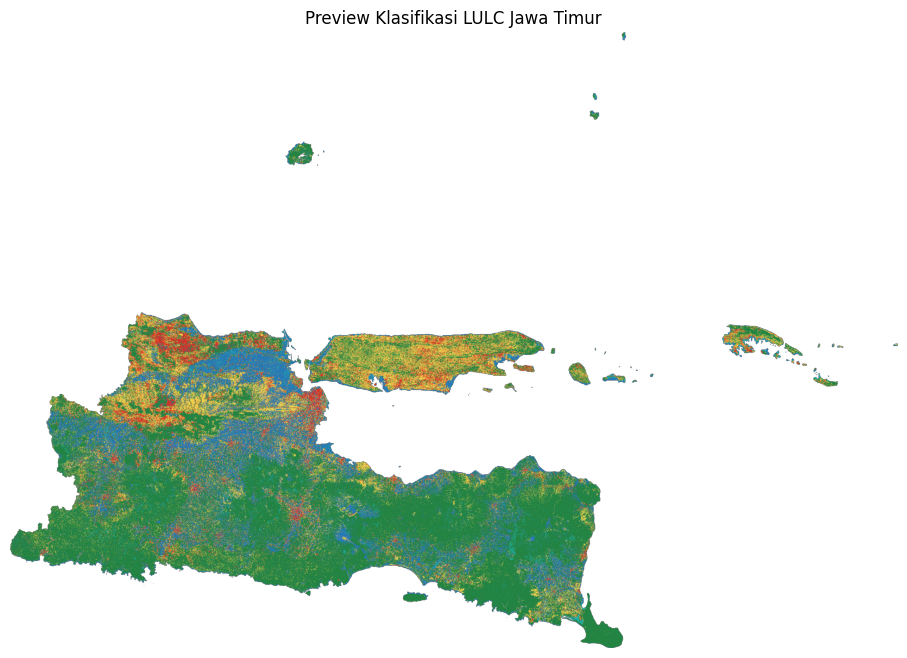

In [5]:

import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
import numpy as np

with rasterio.open(RASTER_PATH) as src:
    skala = 10

    tinggi = max(1, src.height // skala)
    lebar = max(1, src.width // skala)

    raster = src.read(
        1,
        out_shape=(tinggi, lebar),
        resampling=Resampling.nearest
    )

    transform = src.transform
    nodata = src.nodata

# Sembunyikan area NoData
raster_masked = np.ma.masked_equal(raster, nodata)

warna = [
    "#F1D34D",  # 0 Farm Land
    "#D73027",  # 1 Build Up
    "#2878B5",  # 2 Water Body
    "#238443",  # 3 Forest
    "#20B2AA"   # 4 Hutan Mangrove
]

from matplotlib.colors import ListedColormap, BoundaryNorm

cmap = ListedColormap(warna)
norm = BoundaryNorm(
    [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5],
    cmap.N
)

plt.figure(figsize=(12, 8))
plt.imshow(raster_masked, cmap=cmap, norm=norm)
plt.title("Preview Klasifikasi LULC Jawa Timur")
plt.axis("off")
plt.show()


In [7]:

import numpy as np
import rasterio
import folium
from pathlib import Path
from PIL import Image
from io import BytesIO
import base64
from rasterio.enums import Resampling
from folium.plugins import Fullscreen


from pathlib import Path

# Lokasi utama proyek
ROOT = Path(
    r"D:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR revisi"
)

# Pastikan lokasi proyek benar
print("Folder proyek ditemukan:", ROOT.exists())

# Lokasi output peta
OUTPUT_PATH = (
    ROOT / "data" / "processed" / "peta_lulc_interaktif.html"
)

OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)

print("Lokasi output:", OUTPUT_PATH)

# Warna dan nama kelas
kelas = {
    0: ("Farm Land", "#F1D34D"),
    1: ("Build Up", "#D73027"),
    2: ("Water Body", "#2878B5"),
    3: ("Forest", "#238443"),
    4: ("Hutan Mangrove", "#20B2AA"),
}

# Baca raster dengan ukuran kecil agar hemat memori
with rasterio.open(RASTER_PATH) as src:
    scale = min(1, 1800 / max(src.width, src.height))
    height = max(1, int(src.height * scale))
    width = max(1, int(src.width * scale))

    raster = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.nearest
    )

    bounds = src.bounds
    nodata = src.nodata

# Koordinat raster dalam urutan: selatan-barat, utara-timur
image_bounds = [
    [bounds.bottom, bounds.left],
    [bounds.top, bounds.right]
]

# Buat peta dasar satelit
peta = folium.Map(
    location=[-7.5, 112.5],
    zoom_start=8,
    tiles=None
)

folium.TileLayer(
    tiles="OpenStreetMap",
    name="OpenStreetMap",
    overlay=False,
    control=True
).add_to(peta)

folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Tiles © Esri",
    name="Citra Satelit",
    overlay=False,
    control=True
).add_to(peta)

# Buat layer terpisah untuk tiap kelas
for class_id, (nama, warna) in kelas.items():
    rgba = np.zeros((height, width, 4), dtype=np.uint8)
    rgb = tuple(int(warna[i:i+2], 16) for i in (1, 3, 5))

    mask = raster == class_id
    rgba[mask, 0] = rgb[0]
    rgba[mask, 1] = rgb[1]
    rgba[mask, 2] = rgb[2]
    rgba[mask, 3] = 190

    # Area NoData tetap transparan
    if nodata is not None:
        rgba[raster == nodata, 3] = 0

    buffer = BytesIO()
    Image.fromarray(rgba, mode="RGBA").save(buffer, format="PNG")
    encoded = base64.b64encode(buffer.getvalue()).decode("utf-8")

    folium.raster_layers.ImageOverlay(
        image="data:image/png;base64," + encoded,
        bounds=image_bounds,
        name=nama,
        opacity=0.85,
        interactive=False,
        cross_origin=False,
        show=True
    ).add_to(peta)

# Legenda
legend_html = """
<div style="
position: fixed; bottom: 25px; left: 25px; z-index: 9999;
background: white; padding: 12px; border: 1px solid #777;
border-radius: 6px; font-size: 13px;">
<b>Legenda LULC Jawa Timur</b><br>
"""
for nama, warna in kelas.values():
    legend_html += (
        f'<div><span style="display:inline-block;width:12px;height:12px;'
        f'background:{warna};margin-right:6px;"></span>{nama}</div>'
    )
legend_html += "</div>"

peta.get_root().html.add_child(folium.Element(legend_html))

folium.LayerControl(collapsed=False).add_to(peta)
Fullscreen().add_to(peta)

peta.save(str(OUTPUT_PATH))

print("Peta berhasil dibuat:", OUTPUT_PATH.resolve())


Folder proyek ditemukan: True
Lokasi output: D:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR revisi\data\processed\peta_lulc_interaktif.html
Peta berhasil dibuat: D:\semester 5\PROYEK SAINS DATA\LULC_JAWA_TIMUR\LULC JAWA TIMUR revisi\data\processed\peta_lulc_interaktif.html
